### Лабораторная работа №2. Обработка естественного языка (NLP)
* Классический ML: Случайный лес.
* Deep Learning: Embeddings + LSTM (рекуррентная нейросеть).

In [567]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kartohamaster\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [568]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [569]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D, Dropout

#### 1. Загрузка данных

In [570]:
df = pd.read_csv('emails.csv')



print("Размер датасета:", df.shape)
print("Имеющиеся колонки:", df.columns.tolist())
print("\nРаспределение классов (1 - спам, 0 - не спам):")
print(df['spam'].value_counts())
print("\nПроверка на пустые значения:\n", df.isnull().sum())

Размер датасета: (5728, 2)
Имеющиеся колонки: ['text', 'spam']

Распределение классов (1 - спам, 0 - не спам):
spam
0    4360
1    1368
Name: count, dtype: int64

Проверка на пустые значения:
 text    0
spam    0
dtype: int64


In [571]:
# Удаление "Subject: " из начала текста в колонке 'text'
# Символ '^' означает начало строки, а '\s*' удаляет лишние пробелы после двоеточия
df['text'] = df['text'].str.replace(r'^Subject:\s*', '', regex=True, case=False)

# Преобразуем колонку со спамом в целые числа
df['spam'] = df['spam'].astype(int)


# Выведем первые несколько строк, чтобы убедиться, что очистка прошла успешно
display(df[['text']].head())

,text
0,naturally irresistible your corporate identity...
1,the stock trading gunslinger fanny is merrill...
2,unbelievable new homes made easy im wanting t...
3,4 color printing special request additional i...
4,"do not have money , get software cds from here..."


In [572]:
def get_punct_percent(text):
    count = 0 # Счётчик знаков припенания
    for char in text:
        if char in string.punctuation: # Проверка на принадлежность к списку знаков препинания
            count += 1

    return count / len(text) * 100 # Доля знаков препинания в тексте в процентах

In [573]:
def get_digit_percent(text):
    count = 0 # Счётчик цифр
    for char in text:
        if char.isdigit(): # Проверка на принадлежность к цифрам
            count += 1

    return count / len(text) * 100 # Доля цифр в тексте в процентах

In [574]:
df['length'] = df['text'].apply(len) # Рассчёт длины каждого сообщения
df['punct_percent'] = df['text'].apply(get_punct_percent) # Процент знаков препинания
df['digit_percent'] = df['text'].apply(get_digit_percent) # Расчёт процента цифр в тексте
df.head()

,text,spam,length,punct_percent,digit_percent
0,naturally irresistible your corporate identity...,1,1475,9.152542,0.203390
1,the stock trading gunslinger fanny is merrill...,1,589,0.000000,0.000000
2,unbelievable new homes made easy im wanting t...,1,439,1.594533,2.277904
3,4 color printing special request additional i...,1,491,4.887984,6.109980
4,"do not have money , get software cds from here...",1,226,5.309735,0.000000


### 3.1. Визуализация признаков

Для визуализации необходимо построить гистограммы распределения для созданных мета-признаков. Это позволяет визуально оценить, насколько хорошо разделяется спам и обычные сообщения.

Технический нюанс: В датасете дисбаланс классов: обычных сообщений (ham) почти в 7 раз больше, чем спама. Использование стандартной шкалы количества count делает визуализацию неинформативной, гистограмма спама становится незаметной относительно объема обычных сообщений.

Поэтому в настройках графика используются параметры:

    stat='density': Ось Y показывает не количество, а плотность вероятности.
    common_norm=False: Нормируется каждый класс отдельно (площадь под кривой и для спама, и для обычных писем равна 1).

Это позволяет сравнивать форму распределений, игнорируя тот факт, что спама меньше.


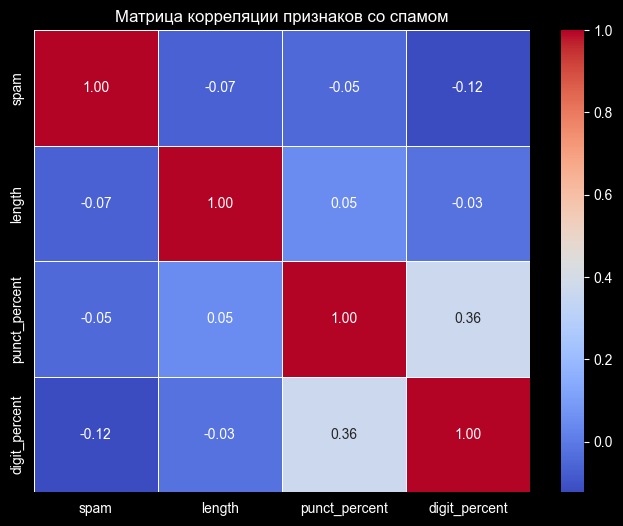

In [575]:
# Отбираем только числовые колонки (включая целевую переменную spam)
numeric_cols = df[['spam', 'length', 'punct_percent', 'digit_percent']]

# Строим тепловую карту (heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матрица корреляции признаков со спамом')
plt.show()

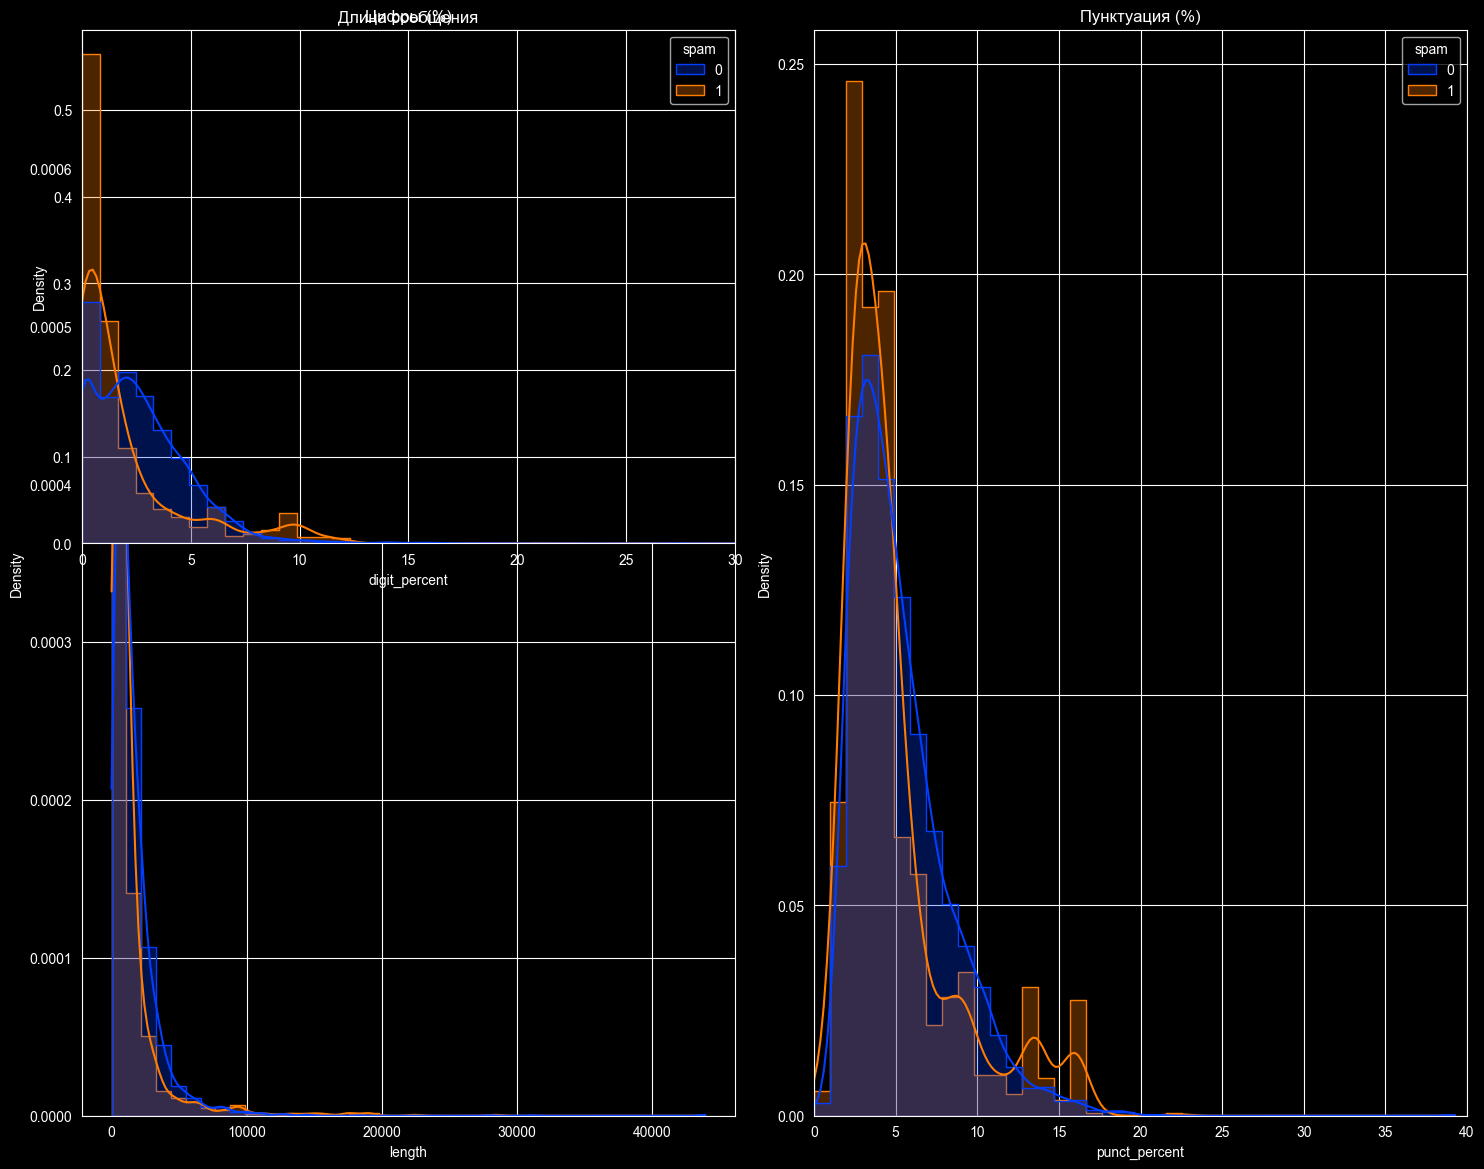

In [576]:
plt.figure(figsize=(30, 12))

kwargs = dict(bins=40, kde=True, stat='density', common_norm=False, palette='bright', element="step", alpha=0.3)

plt.subplot(1, 4, 1)
sns.histplot(data=df, x='length', hue='spam', **kwargs)
plt.title('Длина сообщения')

plt.subplot(1, 4, 2)
sns.histplot(data=df, x='punct_percent', hue='spam', **kwargs)
plt.xlim(0, 40)
plt.title('Пунктуация (%)')


plt.subplot(2, 4, 1)
sns.histplot(data=df, x='digit_percent', hue='spam', **kwargs)
plt.xlim(0, 30)
plt.title('Цифры (%)')

plt.tight_layout()
plt.show()

#### Предобработка текста (Preprocessing)

In [577]:
lemmatizer = WordNetLemmatizer() # Инициализация лемматизатора для приведения слов к канонической форме
stop_words = set(stopwords.words('english')) # Загрузка набора стоп-слов. Set обеспечивает поиск за константное время O(1)

In [578]:
def clean_text(text):

    text = text.lower() # Приведение текста к нижнему регистру

    text_no_punct = "" # Создание буфера для результата
    for char in text:
        if char not in string.punctuation: # Посимвольная фильтрация пунктуации
            text_no_punct += char

    tokens = text_no_punct.split() # Токенизация: разделение текста на отдельные слова

    clean_tokens = [] # Список для нормализованных токенов
    for word in tokens:
        if word not in stop_words: # Фильтрация стоп-слов
            lemma = lemmatizer.lemmatize(word) # Лемматизация
            clean_tokens.append(lemma)

    return " ".join(clean_tokens) # Создание единой строки из всего текста

In [579]:
df['clean_text'] = df['text'].apply(clean_text) # Очистка текста

In [580]:
print("ИСХОДНЫЙ:", df['text'].iloc[0]) # Визуализация результатов
print("ОЧИЩЕННЫЙ:", df['clean_text'].iloc[0])

ИСХОДНЫЙ: naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isoverwhelminq ; but a good  catchy logo , stylish statlonery and outstanding website  will make the task much easier .  we do not promise that havinq ordered a iogo your  company will automaticaily become a world ieader : it isguite ciear that  without good products , effective business organization and practicable aim it  will be hotat nowadays market ; but we do promise that your marketing efforts  will become much more effective . here is the list of clear  benefits : creativeness : hand - made , original logos , specially done  to reflect your distinctive company image . convenience : logo and stationery  are provided in all formats ; easy - to - use content management system letsyou  change your website content and even its structure . promptness : you  will see logo drafts within three business days . affordability : your  ma

####  Подготовка к обучению (Классический ML)

In [581]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Разделяем датафрейм на два множества по классам
spam_messages = df[df['spam'] == 1]
ham_messages = df[df['spam'] == 0]

# 2. Выбираем ровно по 1200 случайных примеров из каждого класса
# random_state=42 гарантирует, что при каждом запуске будут выбираться одни и те же 1200 строк
spam_sampled = spam_messages.sample(n=1200, random_state=42)
ham_sampled = ham_messages.sample(n=1200, random_state=42)

# 3. Объединяем выбранные данные в новый сбалансированный датафрейм
df_balanced = pd.concat([spam_sampled, ham_sampled])

# 4. Перемешиваем строки, чтобы спам и не-спам не шли сплошными блоками
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

# Выделяем вектор признаков и целевую переменную из нового сбалансированного датасета
X = df_balanced['text'] # X - вектор признаков: обработанный текст
y = df_balanced['spam'] # y - целевая переменная

# Разделение выборки на обучающее и тестовые подмножества
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,     # Выделение 20% данных для валидации
    random_state=42,   # Фиксация генератора псевдослучайных чисел для воспроизводимости экспериментов
    stratify=y         # Стратификация выборки. Теперь пропорция 1:1 строго сохранится и в трейне, и в тесте
)

# Проверка результата
print("Размер обучающей выборки:", len(y_train))
print("Баланс классов в обучающей выборке:\n", y_train.value_counts())

Размер обучающей выборки: 1920
Баланс классов в обучающей выборке:
 spam
1    960
0    960
Name: count, dtype: int64


In [582]:
print(f"Размер обучающей выборки: {X_train.shape[0]} сообщений")
print(f"Размер тестовой выборки:  {X_test.shape[0]} сообщений")

Размер обучающей выборки: 1920 сообщений
Размер тестовой выборки:  480 сообщений


Векторизация (TF-IDF)

In [583]:
tfidf_vect = TfidfVectorizer(max_features=1000) # Инициализация векторизатора с ограничением размерности пространства признаков
X_train_tfidf = tfidf_vect.fit_transform(X_train) # Расчёт IDF на тренировочной выборке
X_test_tfidf = tfidf_vect.transform(X_test) # Применение модели

In [584]:
print(f"Размерность матрицы Train: {X_train_tfidf.shape}")
print(f"Размерность матрицы Test:  {X_test_tfidf.shape}")

Размерность матрицы Train: (1920, 1000)
Размерность матрицы Test:  (480, 1000)


Моделирование: Классический алгоритм

В качестве классификатора выбран алгоритм Random Forest (Случайный лес) - ансамбль деревьев решений. Метод работает дольше, но находит более сложные зависимости между словами.

Процесс обучения реализуется через цикл: fit (обучение на train) -> predict (предсказание на test).

Значения гипперпараметров (количество деревьев) определены эксперементальным путём.

In [585]:
rf_model = RandomForestClassifier(
    n_estimators=5000,        # Больше деревьев = более усредненный и стабильный результат
    max_depth=3,            # ОГРАНИЧЕНИЕ 1: Максимальная глубина каждого дерева
    min_samples_split=5,     # ОГРАНИЧЕНИЕ 2: Мин. количество примеров для разделения ветки
    min_samples_leaf=5,      # ОГРАНИЧЕНИЕ 3: Мин. количество примеров в конечном листе
    random_state=422,
               # Использует все ядра процессора для ускорения
)
rf_model.fit(X_train_tfidf, y_train) # Построение зависимостей между TF-IDF векторами и метками классов на тренировочной выборке
y_pred_rf = rf_model.predict(X_test_tfidf) # Генерация прогнозов для тестовой выборки
print("Random Forest обучен.")

Random Forest обучен.


Оценка качества

В задачах спама классы несбалансированы, спама намного меньше, чем обычных писем. Поэтому метрикаAccuracy будет недостаточно информативна.

Метрики для оценки модели:

    Classification Report: Показывает Precision (сколько из найденного спама реально спам), Recall (сколько всего спама мы нашли) и F1-score (среднее)

In [586]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      0.78      0.87       240
           1       0.82      1.00      0.90       240

    accuracy                           0.89       480
   macro avg       0.91      0.89      0.89       480
weighted avg       0.91      0.89      0.89       480



Проверка на переобучение (Overfitting)

Так как классы не сбалансированы, метрика Accuracy (доля правильных ответов) может вводить в заблуждение. Корректно будет сравниват метрику F1-score для класса "Спам" (1). Это покажет, насколько хорошо модель научилась классифицировать спам.

Методика:

    Сделать предсказание на обучающей выборке (Train) и посчитать F1.
    Сравнить результаты с F1 на тестовой выборке (Test).

Интерпретация:

    Если Train F1 ≈ 1.0, а Test F1 ниже — модель просто "зазубрила" конкретные примеры спама из обучения, но не поняла общего принципа. Это переобучение.
    Если разница небольшая (менее 0.05–0.1) — модель работает стабильно.


In [587]:
from sklearn.metrics import f1_score

y_pred_train = rf_model.predict(X_train_tfidf) # Генерация прогнозов для обучающей выборки
f1_train = f1_score(y_train, y_pred_train, pos_label=1) # Расчёт F1-score на обучающих данных
f1_test = f1_score(y_test, y_pred_rf, pos_label=1) # Расчёт F1-score на тестовых данных для оценки обобщающей способности модели

In [588]:
print(f"F1-score на обучении (Train): {f1_train:.4f}")
print(f"F1-score на тесте    (Test):  {f1_test:.4f}")

F1-score на обучении (Train): 0.9023
F1-score на тесте    (Test):  0.8989


Моделирование: Глубокое обучение (LSTM)
7.1. Подготовка тензоров (Tokenization & Padding)

В отличие от классических алгоритмов, нейросети требуют строгой стандартизации размерности входа. Приведение текстов к единому вектору фиксированной длины является обязательным условием для выполнения матричных операций

В чем проблема? Тексты имеют разную длину: одно SMS — 5 слов, другое — 50. Нейросеть обрабатывает данные пакетами (batches). Пакет — это прямоугольная матрица (Тензор). Подать в матрицу строки разной длины будет некорректно и это вызовет ошибку размерности.

Решение: Привести все тексты к единому стандарту (формату фиксированной длины) через три этапа:

    Токенизация (Indexing): Создание словаря из Топ-3000 самых частых слов. Каждому слову присвоим уникальный номер (индекс).
        Пример: {"hello": 1, "world": 2, ...}
        Все слова, не попавшие в топ (редкие), необходимо заменить на специальный токен <OOV> (Out Of Vocabulary), чтобы не терять информацию о том, что "здесь было слово".

    Индексация токенов: Замена текстовых элементов на их числовые эквиваленты (индексы) в соответствии со словарем. Текстовая строка преобразуется в массив целых чисел.
        Было: "Hello world"
        Стало: [1, 2]

    Паддинг (Padding): Приведение входных последовательностей к стандартной длине в 150 чисел.
        Если меньше: Дополнить нулями (0). Нейросеть научится игнорировать эти нули (так как у них нет смысла).
        Если больше: Сократить "хвост".


In [589]:
MAX_WORDS = 1000 # Размер словаря
MAX_LEN = 200    # Длина входной последовательности

In [590]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Выделяем по 1200 случайных примеров каждого класса
spam_sampled = df[df['spam'] == 1].sample(n=1200, random_state=42)
ham_sampled = df[df['spam'] == 0].sample(n=1200, random_state=42)

# 2. Объединяем и перемешиваем
df_balanced = pd.concat([spam_sampled, ham_sampled]).sample(frac=1, random_state=42).reset_index(drop=True)

# 3. Разделение выборки на обучающее и тестовые множества
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df_balanced['text'], df_balanced['spam'],            # Используем сырой текст для LSTM
    test_size=0.2,
    random_state=42,
    stratify=df_balanced['spam']                         # Фиксируем баланс классов 1:1
)

print("Размер обучающей выборки (LSTM):", len(y_train))
print("Баланс классов:\n", y_train.value_counts())

Размер обучающей выборки (LSTM): 1920
Баланс классов:
 spam
1    960
0    960
Name: count, dtype: int64


In [591]:
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>") # Инициализация токенизатора
tokenizer.fit_on_texts(X_train_raw)                           # Обучение токенизатора

In [592]:
sequences_train = tokenizer.texts_to_sequences(X_train_raw) # Преобразование текстовых строк в последовательности целочисленных индексов
sequences_test = tokenizer.texts_to_sequences(X_test_raw)
# seq_test= tokenizer.texts_to_sequences(" ")

Обоснование стратегии выравнивания (Padding Strategy)

Выбор параметров padding (заполнение) и truncating (усечение) диктуется архитектурными особенностями рекуррентных нейронных сетей (RNN/LSTM).

Почему padding='pre' (Заполнение нулями в начале)?** Архитектура LSTM обрабатывает входную последовательность пошагово, обновляя внутреннее состояние памяти (hidden state). Если использовать padding='post' (добавление нулей в конце), сеть после прочтения информативной части текста будет вынуждена обрабатывать цепочку нулей вплоть до конца вектора. Это приводит к эффекту информационного затухания: к моменту предсказания на последнем шаге контекст реальных слов может быть "размыт" пустыми итерациями. Размещение нулей в начале позволяет сети сохранить актуальный контекст в памяти непосредственно перед слоем классификации.

Эксперимент: Демонстрация проблемы затухания сигнала

Распространенной ошибкой при работе с LSTM является использование padding='post'. Предлагается провести эксперимент для выявления этой ошибки:

    Измените в коде ниже параметр на padding='post'.
    Запустите обучение модели.
    Ожидаемый результат: Вероятнее всего, метрика Recall для класса spam упадет до 0.00.
        Причина: Из-за затухания сигнала модель перестанет различать признаки спама и перейдет к стратегии наименьшего сопротивления — будет предсказывать мажоритарный класс («не спам») для всех примеров, показывая формально высокую точность (Accuracy ~87%), но нулевую эффективность.


In [593]:
X_train_seq = pad_sequences(sequences_train, maxlen=MAX_LEN, padding='pre', truncating='post')
X_test_seq = pad_sequences(sequences_test, maxlen=MAX_LEN, padding='pre', truncating='post')
# testh = pad_sequences(seq_test, maxlen=MAX_LEN, padding='pre', truncating='post')

In [594]:
print(f"Пример текста:\n{X_train_raw.iloc[0]}")
print(f"\nПример последовательности:\n{X_train_seq[0]}")
print(f"\nРазмерность входа для сети: {X_train_seq.shape}")

Пример текста:
i know your company !  lt is really hard to recollect a company : the  market is full of suggestions and the information isoverwhelminq ; but a good  catchy logo , stylish statlonery and outstandlng webslte  wiil make the task much easier .  we do not promise that having ordered a iogo your  company will automaticaiiy become a worid ieader : it isguite clear that  without good products , effective business organization and practicable aim it  will be hotat nowadays market ; but we do promise that your marketing efforts  will become much more effective . here is the list of clear  benefits : creativeness : hand - made , original logos , specially done  to reflect your distinctive company image . convenience : logo and stationery  are provided in all formats ; easy - to - use content management system letsyou  change your website content and even its structure . promptness : you  will see logo drafts within three business days . affordability : your  marketing break - thro

7.1. Создание модели

Мы используем архитектуру Sequential (последовательную):

    Embedding Layer: Превращает индексы (числа) в плотные векторы. Именно здесь сеть учит семантическую близость слов.
    LSTM Layer: Рекуррентный слой с памятью. Он читает текст слева направо.
    Output Layer (Dense): Один нейрон с активацией sigmoid, который выдает вероятность спама (от 0 до 1).

model = Sequential() # Инициализация последовательной архитектуры нейронной сети

In [595]:
model = Sequential() # Инициализация последовательной архитектуры нейронной сети
model.add(Embedding(input_dim=MAX_WORDS, output_dim=64, input_length=MAX_LEN)) # Преобразование индексов в плотные векторы
model.add(SpatialDropout1D(0.5)) # Регуляризация путем исключения целых карт признаков
model.add(LSTM(32, dropout=0.4, recurrent_dropout=0.7)) # Слой LSTM с регуляризацией входов и рекурсии
model.add(Dense(1, activation='sigmoid')) # Выходной слой: сигмоидальная активация для бинарной классификации
model.compile(loss='binary_crossentropy', optimizer='adam') # Конфигурация обучения: функция потерь и оптимизатор
model.summary() # Вывод сводной информации об архитектуре модели

C:\Users\kartohamaster\PycharmProjects\OODlabs\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_23 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_23            │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_23 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Обучение

Нейросети склонны к переобучению (запоминанию примеров наизусть) на маленьких датасетах. Чтобы этого избежать, мы используем EarlyStopping: если ошибка на валидации (val_loss) перестает падать в течение 2 эпох, обучение останавливается досрочно.

In [596]:
# Запуск итерационного процесса обучения

from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(
    X_train_seq, y_train,     # Передача входных последовательностей и целевых меток
    epochs=10,                # Установление максимального числа эпох
    batch_size=64,            # Размер пакета (батча) для обновления весов
    validation_split=0.1,     # Резервирование 10% выборки для валидации в реальном времени
    callbacks=[early_stop],   # Подключение callback-функции ранней остановки
    verbose=1                 # Активация вывода прогресса обучения
)

Epoch 1/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - loss: 0.6884 - val_loss: 0.6869
Epoch 2/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.6780 - val_loss: 0.6703
Epoch 3/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.6421 - val_loss: 0.6186
Epoch 4/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.5726 - val_loss: 0.5114
Epoch 5/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.4739 - val_loss: 0.3457
Epoch 6/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.3759 - val_loss: 0.2709
Epoch 7/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.3132 - val_loss: 0.2138
Epoch 8/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.2769 - val_loss: 0.2033
Epoch 9/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.2560 - val_loss: 0.1792
Epoch 10/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.2349 - val_loss: 0.1810


### 7.3. Оценка результатов LSTM
Построим график обучения (Loss), чтобы убедиться, что сеть сходится.
Затем сделаем предсказания на тестовой выборке и сравним метрики с классическими моделями.

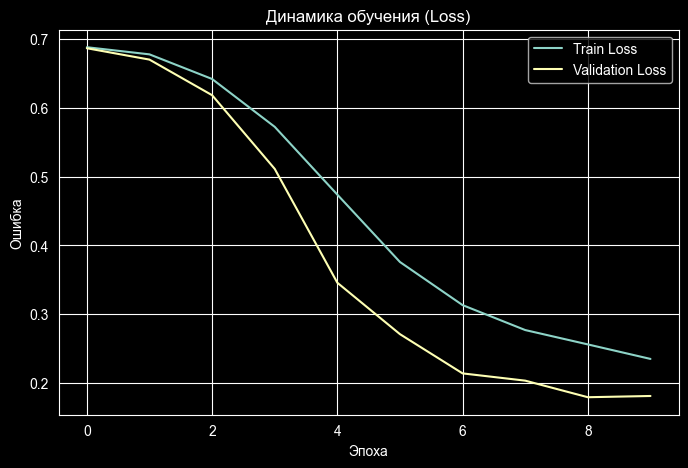

In [597]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Динамика обучения (Loss)')
plt.xlabel('Эпоха')
plt.ylabel('Ошибка')
plt.legend()
plt.show()

In [598]:
# Предсказание на тесте
# Нейросеть выдает вероятность (например, 0.85). Нам нужно округлить: > 0.5 это спам (1)
y_pred_dl_prob = model.predict(X_test_seq)
# testn= model.predict(testh)
# print("test :",testn)
y_pred_dl = (y_pred_dl_prob > 0.5).astype(int)
print(classification_report(y_test, y_pred_dl))


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       240
           1       0.93      0.94      0.94       240

    accuracy                           0.94       480
   macro avg       0.94      0.94      0.94       480
weighted avg       0.94      0.94      0.94       480

